# Swing/take decision maps

Where should a hitter swing, count by count? The eye model already has every piece needed to draw it. For any location and count:

- **EV(take)** = P(called strike) × (run value of a called strike in this count) + (1 − P) × (run value of a ball)
- **EV(swing)** = the swing-value model's expected run value of swinging at that pitch, for an average D1 hitter
- **swing − take** = runs an average hitter gains by swinging instead of taking. **Red: swing. Blue: take.** The black line is break-even.

These maps are exactly what eye scores a hitter against. Eye is `(swung − P(swing)) × (swing − take)`, so the color under each pitch says which decision gains and how much is at stake.

**Model:** the shipped D1 2026 artifact (`eye_store.load("D1", "2026")`). Bunts are still in its swing-value training data, a small effect (`eye_v1_challenges.ipynb`, section 3a). **"All pitches"** averages the three families using the league's pitch mix in that count. Height is ignored, as in v1.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from scipy.ndimage import gaussian_filter

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pipeline_v2").is_dir())
sys.path.insert(0, str(REPO))
from backend.models import eye_store, eye_v1
from delispice_app.report import ZONE          # the app's strike zone (feet)

pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(3)

LEVEL, YEAR = "D1", "2026"
model = eye_store.load(LEVEL, YEAR)
RV = {(r["Balls"], r["Strikes"]): (r["rv_strike"], r["rv_ball"]) for r in model.count_rv.iter_rows(named=True)}
FAMILIES = ["Fastball", "Breaking", "Offspeed"]
COUNTS = [(b, s) for b in range(4) for s in range(3)]

# league pitch mix by count and batter side (0 = R, 1 = L), for the "All pitches" maps
season = REPO / "pipeline_v2" / "serving" / "pitches" / LEVEL / YEAR / f"{LEVEL.lower()}_{YEAR}.parquet"
mix = (eye_v1.prepare(pl.read_parquet(season, columns=eye_v1._PITCH_COLS))
             .filter(pl.col("PitchFamily").cast(pl.Utf8).is_in(FAMILIES))
             .group_by("BatterSide", "Balls", "Strikes", "PitchFamily").len()
             .with_columns((pl.col("len") / pl.col("len").sum().over("BatterSide", "Balls", "Strikes")).alias("share")))
MIX = {(r["BatterSide"], r["Balls"], r["Strikes"], r["PitchFamily"]): r["share"] for r in mix.iter_rows(named=True)}

# plotting grid (feet) and style: blue <-> red around gray, red = swing
xs, zs = np.linspace(-1.75, 1.75, 141), np.linspace(0.75, 4.25, 141)
XX, ZZ = np.meshgrid(xs, zs)
CELL_SQIN = (xs[1] - xs[0]) * (zs[1] - zs[0]) * 144
IN_BOX = (np.abs(XX) <= ZONE["h"]) & (ZZ >= ZONE["b"]) & (ZZ <= ZONE["t"])
INK, MUTED = "#0b0b0b", "#52514e"
DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#f19c9b", "#c23b3a"])
SEQ = LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({"axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.titlecolor": INK, "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})


def surfaces(balls, strikes, family="All pitches", side=0):
    """P(called strike), EV(take), EV(swing) and swing − take on the grid, for one count."""
    fams = FAMILIES if family == "All pitches" else [family]
    weights = [MIX.get((side, balls, strikes, f), 0.0) if family == "All pitches" else 1.0 for f in fams]
    ev_swing = 0
    for f, w in zip(fams, weights):
        g = pd.DataFrame({"BatterSide": side, "Balls": balls, "Strikes": strikes,
                          "PlateLocHeight": ZZ.ravel(), "PlateLocSide": XX.ravel(),
                          "PitchFamily": pd.Categorical([f] * XX.size, categories=eye_v1.FAM_CATS)})
        ev_swing = ev_swing + w * model.ev.predict(g[eye_v1.EV_FEATS]) / sum(weights)
    p_strike = model.ump.predict_proba(g[eye_v1.UMP_FEATS])[:, 1]       # the call doesn't depend on family
    rv_strike, rv_ball = RV[(balls, strikes)]
    ev_take = p_strike * rv_strike + (1 - p_strike) * rv_ball
    out = {"P(called strike)": p_strike, "EV(take)": ev_take, "EV(swing)": ev_swing, "swing − take": ev_swing - ev_take}
    return {k: np.asarray(v).reshape(XX.shape) for k, v in out.items()}


def draw_break_even(ax, d):
    """The swing/take line. Lightly smoothed (only the line, not the colors): where swinging and
    taking are nearly tied, the raw tree surface wobbles around zero and draws a ragged line."""
    if d.min() < 0 < d.max():
        ax.contour(xs, zs, gaussian_filter(d, 2), levels=[0], colors=INK, linewidths=1.5)


def swing_zone_pct(d):
    """Swing-zone area (where swinging beats taking) as a % of the rulebook box's area."""
    return 100 * (d > 0).sum() / IN_BOX.sum()


def draw_zone(ax):
    ax.add_patch(Rectangle((-ZONE["h"], ZONE["b"]), 2 * ZONE["h"], ZONE["t"] - ZONE["b"],
                           fill=False, ec=INK, ls="--", lw=1))
    ax.set_aspect("equal")


def side_label(side):
    return "plate side (ft)   ← away | inside →" if side == 0 else "plate side (ft)   ← inside | away →"

## How one map is built (1-2 count, all pitches)

Left to right: the umpire model's strike probability; what taking is worth (mostly a strikeout risk on strikes, a 2-2 count on balls); what swinging is worth; and the difference. Where the umpire is likely to ring up a take, taking is expensive, so the swing zone grows past the box.

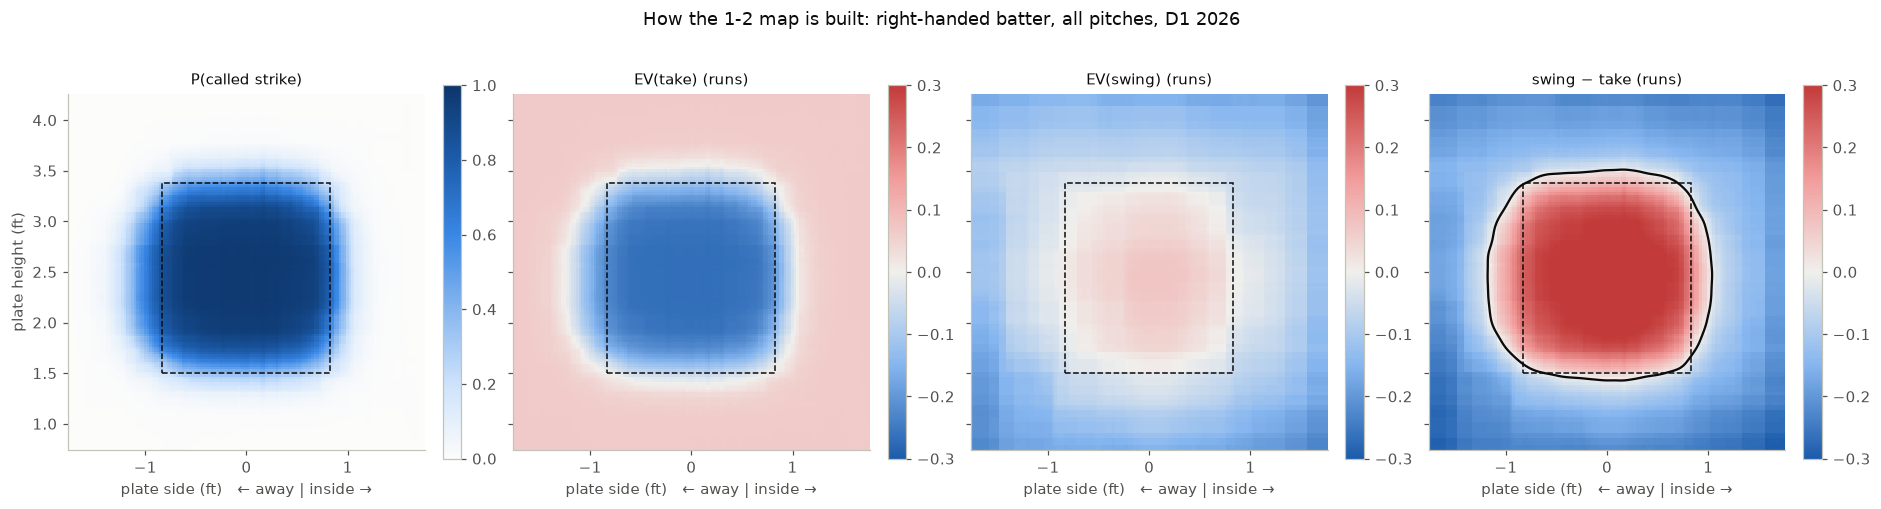

In [2]:
B, S = 1, 2
surf = surfaces(B, S)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6), sharey=True, layout="constrained")
specs = [("P(called strike)", SEQ, (0, 1)), ("EV(take)", DIV, (-0.3, 0.3)),
         ("EV(swing)", DIV, (-0.3, 0.3)), ("swing − take", DIV, (-0.3, 0.3))]
for ax, (key, cmap, (lo, hi)) in zip(axes, specs):
    im = ax.pcolormesh(xs, zs, surf[key], cmap=cmap, vmin=lo, vmax=hi, shading="auto")
    if key == "swing − take":
        draw_break_even(ax, surf[key])
    draw_zone(ax)
    ax.set_title(key if key == "P(called strike)" else f"{key} (runs)")
    ax.set_xlabel(side_label(0))
    fig.colorbar(im, ax=ax, shrink=0.8)
axes[0].set_ylabel("plate height (ft)")
fig.suptitle(f"How the {B}-{S} map is built: right-handed batter, all pitches, {LEVEL} {YEAR}", color=INK)
plt.show()

## Every count (right-handed batter, all pitches)

Same color scale in every panel, so **color strength shows the stakes**: early counts are pale because a single decision is worth little there, and 3-2 is saturated. The black line is where an average hitter is indifferent between swinging and taking, so inside it is the count's **swing zone**.

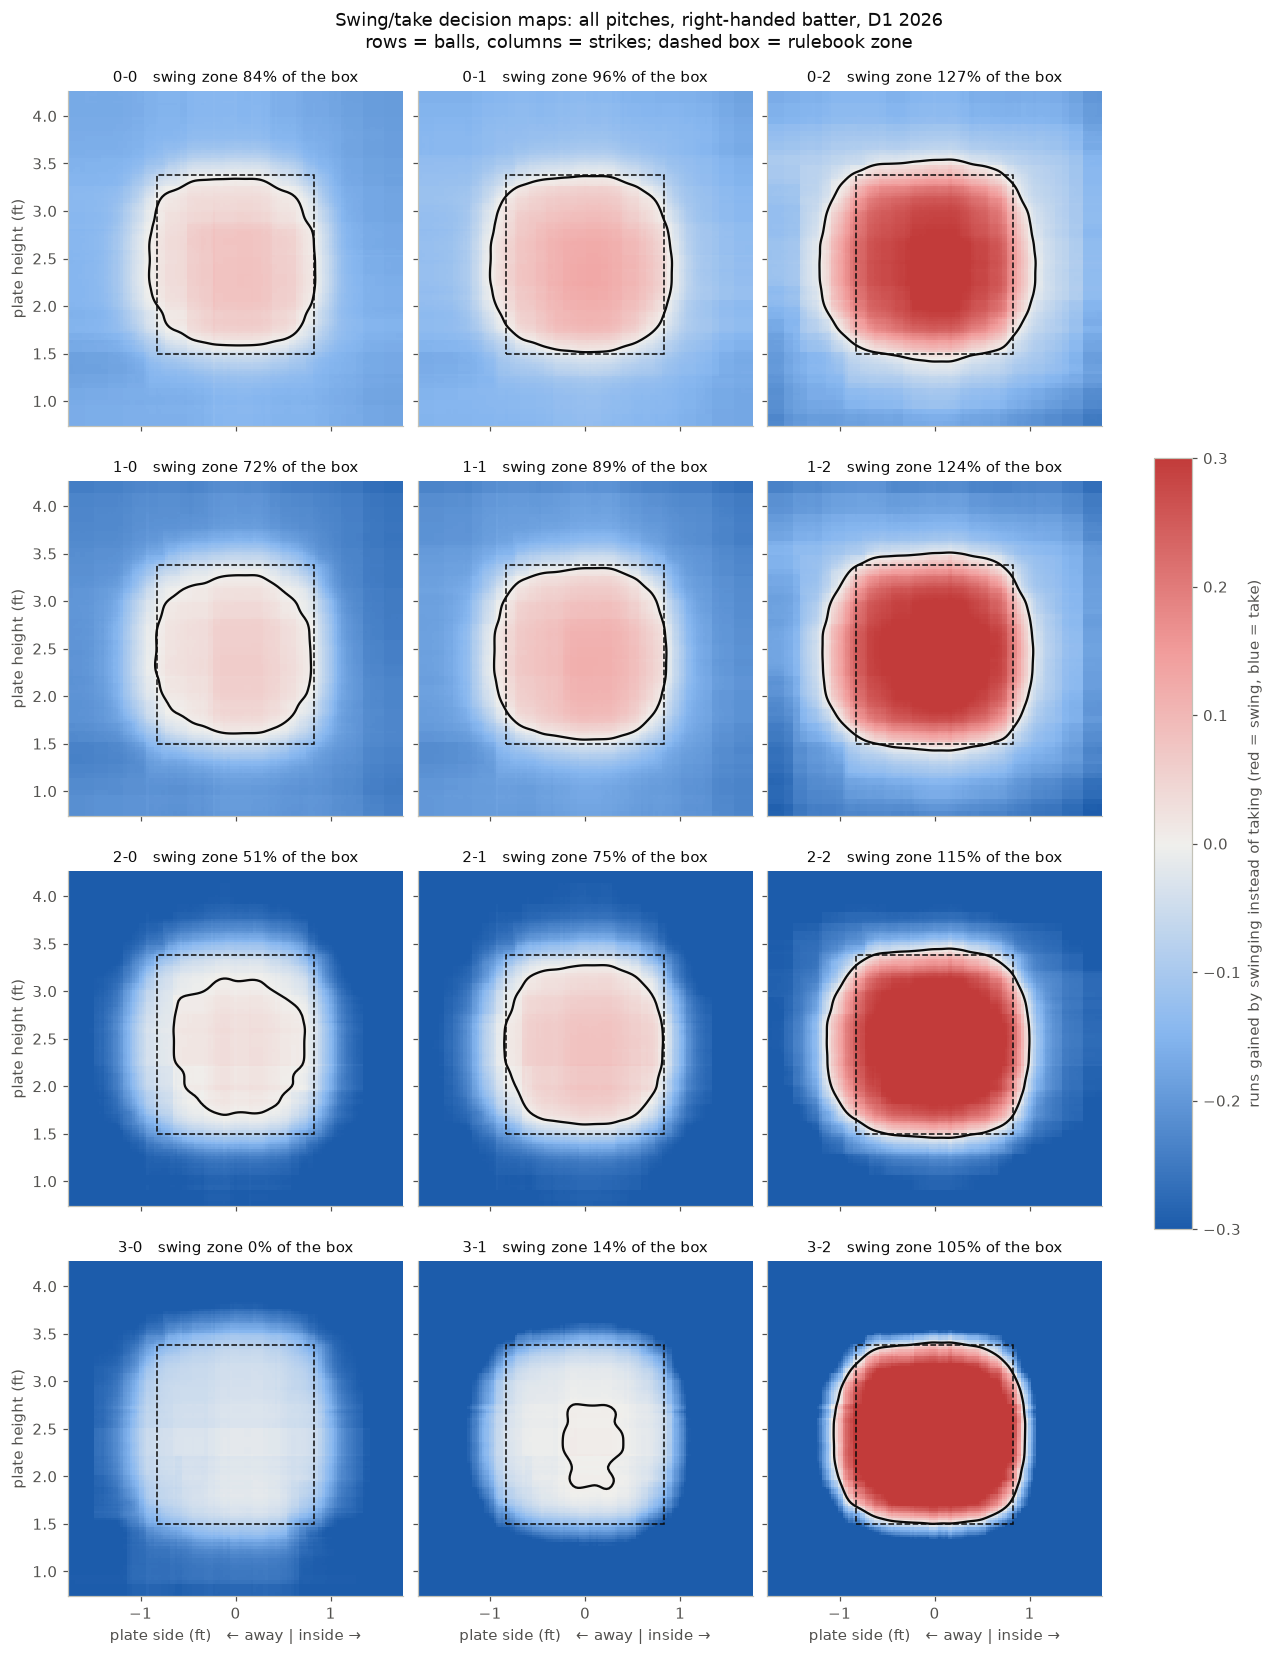

In [3]:
def decision_maps(family="All pitches", side=0, vmax=0.3):
    fig, axes = plt.subplots(4, 3, figsize=(11.5, 15), sharex=True, sharey=True, layout="constrained")
    for b, s in COUNTS:
        ax = axes[b, s]
        d = surfaces(b, s, family, side)["swing − take"]
        im = ax.pcolormesh(xs, zs, d, cmap=DIV, vmin=-vmax, vmax=vmax, shading="auto")
        draw_break_even(ax, d)
        draw_zone(ax)
        ax.set_title(f"{b}-{s}   swing zone {swing_zone_pct(d):.0f}% of the box")
    for ax in axes[-1]:
        ax.set_xlabel(side_label(side))
    for ax in axes[:, 0]:
        ax.set_ylabel("plate height (ft)")
    fig.colorbar(im, ax=axes, shrink=0.5, label="runs gained by swinging instead of taking (red = swing, blue = take)")
    hand = "right" if side == 0 else "left"
    fig.suptitle(f"Swing/take decision maps: {family.lower()}, {hand}-handed batter, {LEVEL} {YEAR}\n"
                 f"rows = balls, columns = strikes; dashed box = rulebook zone", color=INK)
    plt.show()


decision_maps()

### The swing zone by count, in numbers

Size of the swing zone (where swinging beats taking) compared with the rulebook box, and how much is at stake at the extremes of each map.

In [4]:
rows = []
for b, s in COUNTS:
    d = surfaces(b, s)["swing − take"]
    rows.append({"count": f"{b}-{s}",
                 "swing zone (sq in)": (d > 0).sum() * CELL_SQIN,
                 "as % of the box": swing_zone_pct(d),
                 "% of the box where swinging wins": 100 * (d[IN_BOX] > 0).mean(),
                 "most gained by swinging (runs)": d.max(),
                 "most gained by taking (runs)": -d.min()})
pl.DataFrame(rows)

count,swing zone (sq in),as % of the box,% of the box where swinging wins,most gained by swinging (runs),most gained by taking (runs)
str,f64,f64,f64,f64,f64
"""0-0""",385.290,84.073,82.129,0.086,0.194
"""0-1""",438.120,95.601,89.120,0.129,0.183
"""0-2""",583.920,127.416,98.429,0.326,0.249
"""1-0""",330.840,72.192,72.054,0.063,0.273
"""1-1""",407.790,88.983,85.271,0.115,0.264
"""1-2""",569.610,124.293,98.665,0.344,0.297
"""2-0""",234.720,51.218,51.218,0.036,0.383
"""2-1""",344.250,75.118,74.764,0.085,0.389
"""2-2""",525.870,114.749,97.113,0.370,0.413


**Reading it:**

- **Early and even counts (0-0, 0-1, 1-1):** the swing zone covers 84–96% of the box. Even at 0-0, an average hitter should take the outer edges of the rulebook zone.
- **Hitter's counts shrink it:** 1-0 is 72%, 2-1 is 75% and 2-0 is 51%. 3-1 is only 14%, and it is nearly a coin flip there: swinging gains at most 0.011 runs anywhere.
- **At 3-0 taking always wins** for an average D1 hitter (swing zone 0%). The walk is so close that even a middle-middle strike is worth more taken. This is the average-hitter answer, and it's if anything generous: section 4 of `eye_v1_challenges.ipynb` showed that 3-0 swings come from better hitters than average, so the swing value here is optimistic. A green-lit hitter with a real bat can still beat it.
- **Two strikes grow it past the box:** 0-2 is 127%, 1-2 124%, 2-2 115% and 3-2 105%, covering 94–98% of the box itself. Taking a pitch the umpire might call costs a strikeout, so protecting the plate pays.
- **The stakes climb with the count:** the most a single decision is worth goes from about 0.1–0.2 runs early to 0.74 at 3-2 (taking a ball instead of chasing it).

## By pitch family

Swing-zone size (as % of the box) for each family, right-handed batter:

In [5]:
pl.DataFrame([{"count": f"{b}-{s}", **{f: swing_zone_pct(surfaces(b, s, f)["swing − take"]) for f in FAMILIES}}
              for b, s in COUNTS])

count,Fastball,Breaking,Offspeed
str,f64,f64,f64
"""0-0""",83.248,85.016,84.780
"""0-1""",95.130,95.189,97.899
"""0-2""",129.360,126.100,129.772
"""1-0""",71.917,72.113,72.486
"""1-1""",89.002,88.374,90.770
"""1-2""",126.139,123.350,125.255
"""2-0""",49.902,53.142,49.784
"""2-1""",74.980,73.998,76.316
"""2-2""",115.613,113.688,115.299


**Family barely moves the maps.** The swing zone is within about 3 points across fastballs, breaking balls and offspeed in every count except 3-1 (6% / 23% / 11%), where swinging and taking are so close to tied (at most 0.011 runs apart) that tiny differences move the line a lot. The take side is identical by design (the umpire model ignores family), and in this model the value of *swinging* at a given spot barely depends on pitch type either. That matches the held-out test in `eye_v1_challenges.ipynb` (1a), where family added only about 2% to the swing-value model's skill.

What does change by family is how often hitters swing: they chase breaking balls far more (challenges notebook, 1b). So breaking balls are where hitters' *decisions* separate, not where the map differs. The breaking-ball maps for reference:

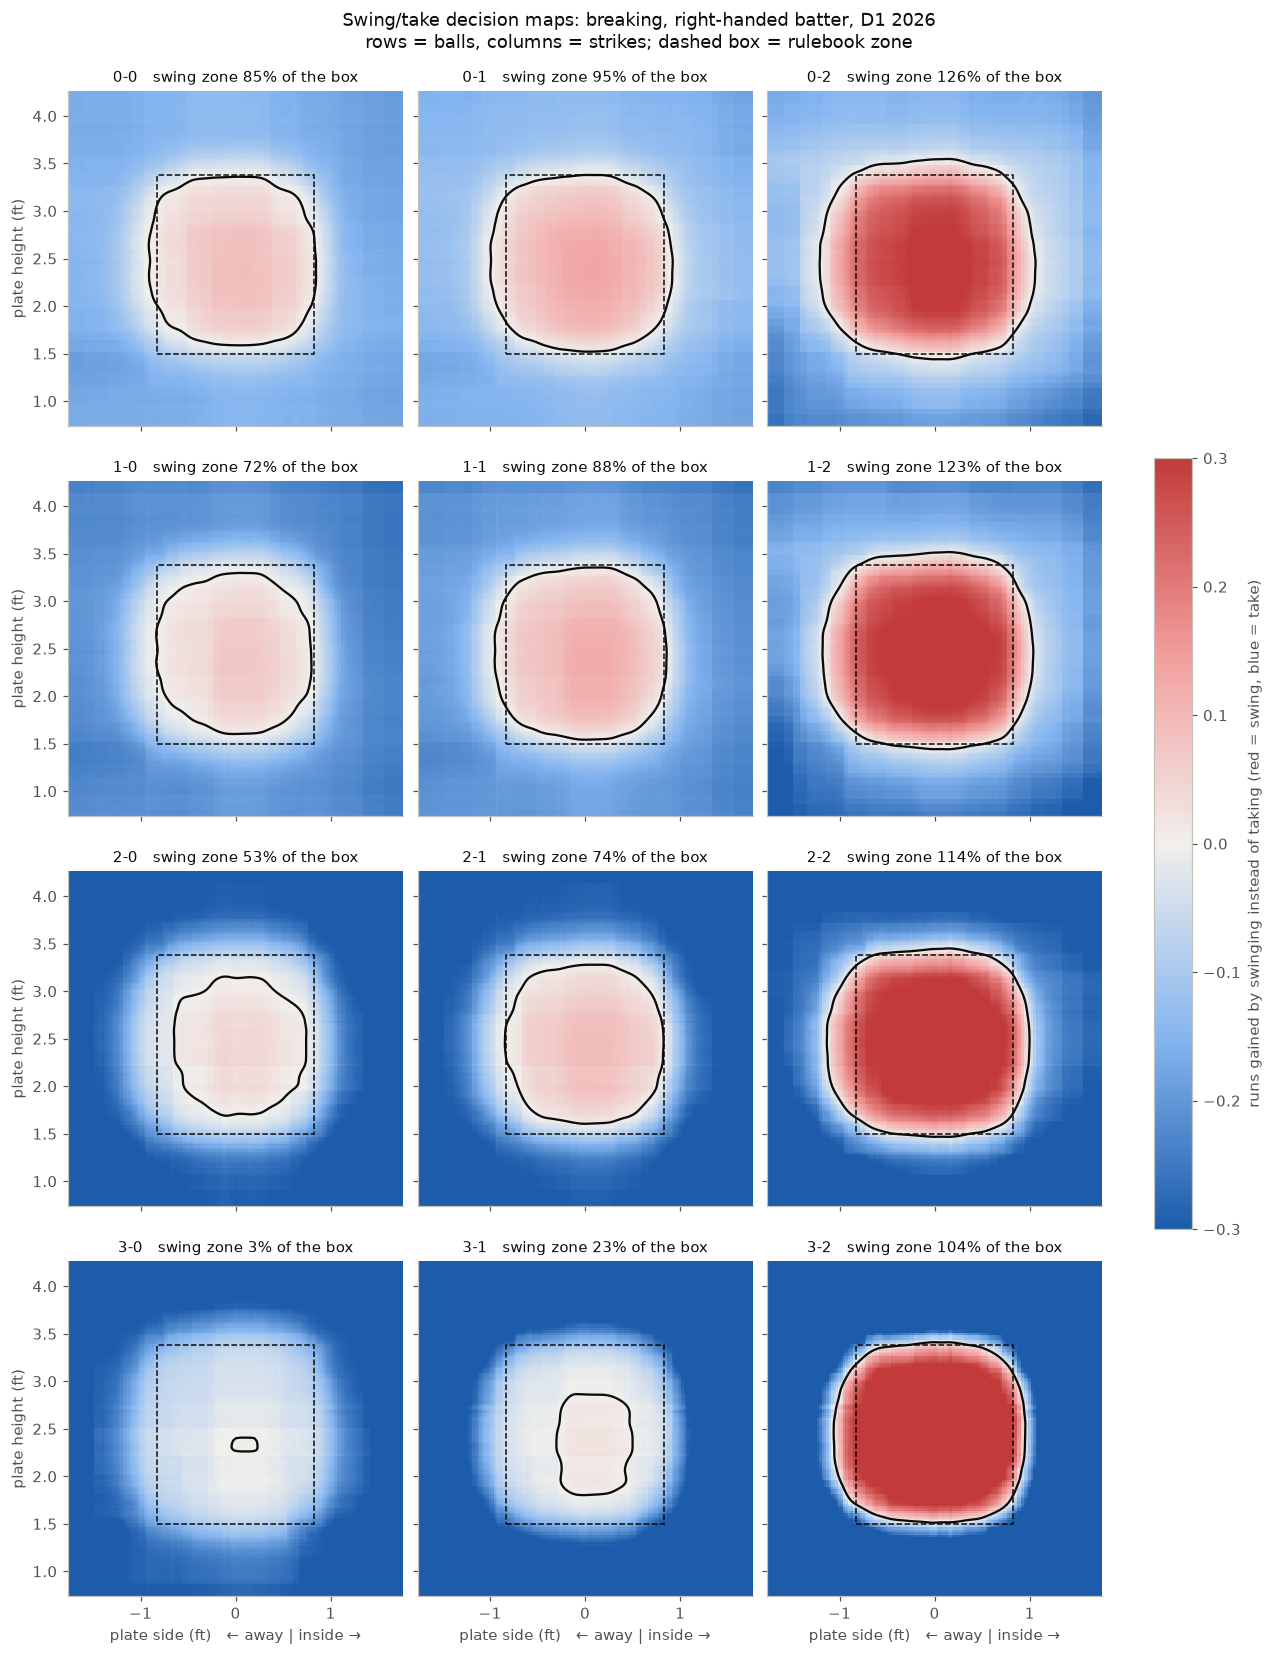

In [6]:
decision_maps("Breaking")

## Draw your own

`decision_maps(family, side)` takes `family` = "All pitches", "Fastball", "Breaking" or "Offspeed", and `side` = 0 for a right-handed batter or 1 for a left-handed one. `surfaces(balls, strikes, family, side)` returns the four grids behind any single map.

Two notes on reading these maps:

- **They are the league-average hitter's maps.** A hitter with a better bat has a bigger real swing zone than the map shows, and eye deliberately ignores that.
- **They are model surfaces, not raw data.** Each map is smoothed by the three LightGBM models, so it has no empty bins. The flip side is that the edges far outside the zone (where few pitches are swung at) are the least certain part.

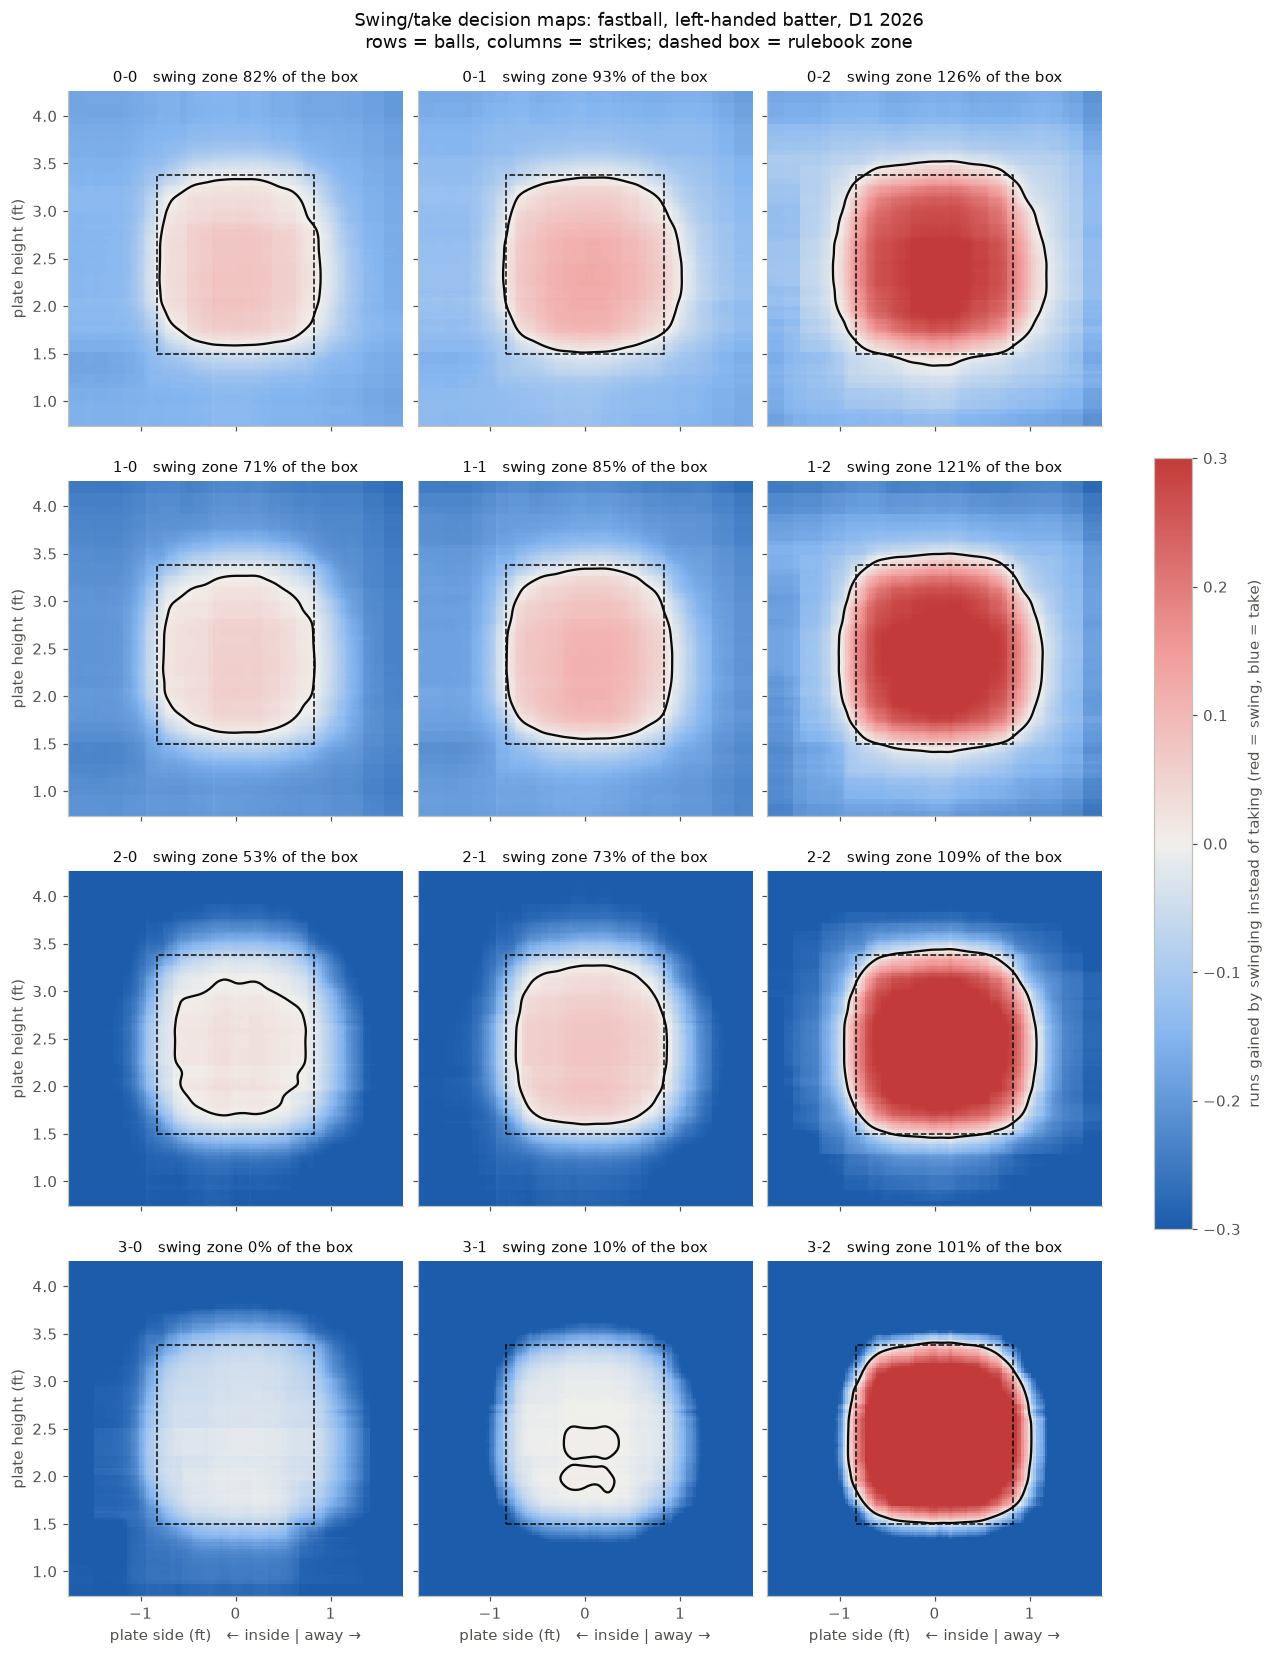

In [7]:
decision_maps("Fastball", side=1)